# Week 3: NLP Pipeline v1
## University Knowledge Assistant (RAG) · Group 4

**Primary NLP component: sentence embeddings for semantic retrieval and semantic similarity.**

Week 2 showed three problems with the keyword baseline. This notebook adds one NLP component, a sentence-embedding model, and uses it at each of the three weak points:

| Week-2 finding | What v1 does |
|---|---|
| Right passage often not ranked first (paraphrased questions) | **Hybrid retrieval**: BM25 score + semantic score. The semantic score of a chunk is the best cosine similarity between the question and any sentence in that chunk |
| Right passage, wrong sentence picked as the answer | **Semantic answer selection**: return the sentence of the cited chunk that is most similar in meaning to the question (still copied word for word) |
| Keyword confidence is a weak "do I know this?" signal | **Lexical + semantic confidence**: average of keyword coverage and semantic similarity; refuse below a threshold tuned on dev |

Embedding model: `sentence-transformers/all-MiniLM-L6-v2` (384-dim, 22M parameters, runs on CPU in seconds).

Everything is tuned on the **dev** set only. The **test** set is the same held-out set as Week 2, with the same metrics, so the comparison with the baseline is direct.

| Section | Content |
|---|---|
| §0 | Setup |
| §1 | Data (Week-2 pipeline, unchanged) |
| §2 | Baseline reproduced (frozen Week-2 settings) |
| §3 | NLP component: embeddings + semantic similarity |
| §4 | Tuning on dev |
| §5 | Final evaluation on test: v1 vs baseline |
| §6 | Ablation and error analysis |
| §7 | Pipeline in action |
| §8 | Tests against the requirements |
| §9 | Saved outputs and summary |

Put `Student_Resource_Book__SRB__2026.pdf` in the same folder as this notebook (on Colab you will be asked to upload it), then **Run All**.

## 0. Setup

In [6]:
# Install anything missing (works on local Jupyter)
import importlib.util, subprocess, sys
for pip_name, module in [("pymupdf", "pymupdf"), ("rank_bm25", "rank_bm25"), ("nltk", "nltk"),
                         ("scikit-learn", "sklearn"), ("pandas", "pandas"), ("matplotlib", "matplotlib"),
                         ("scipy", "scipy"), ("sentence-transformers", "sentence_transformers")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import os, re, time, json, unicodedata
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import pymupdf
except ImportError:                                 # older PyMuPDF versions only expose `fitz`
    import fitz as pymupdf

from rank_bm25 import BM25Okapi
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from scipy.stats import binomtest
import torch
from sentence_transformers import SentenceTransformer

# Set your local file path correctly using an 'r' prefix for Windows paths
PDF_PATH = r'c:\Users\Sharvari\Downloads\Student Resource Book (SRB) 2026.pdf'
OUT_DIR = "week3_outputs"                    # results of this notebook
WEEK2_DIR = "week2_outputs"                  # optional: used only to double-check the split
EMB_MODEL = os.environ.get("SRB_EMB_MODEL", "sentence-transformers/all-MiniLM-L6-v2")
SEED = 42

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 110)

# Verify the file exists locally
if not os.path.exists(PDF_PATH):
    raise FileNotFoundError(f"Could not find the SRB PDF at: {PDF_PATH}. Please check if the file name or path is correct.")

print("Using:", PDF_PATH, "| embedding model:", EMB_MODEL)

Using: c:\Users\Sharvari\Downloads\Student Resource Book (SRB) 2026.pdf | embedding model: sentence-transformers/all-MiniLM-L6-v2


## 1. Data (Week-2 pipeline, unchanged)

The code in this section is copied from the Week-2 notebook without changes: load the SRB page by page, clean it, keep the 60 rule/policy pages, tag sections, chunk, tokenise, load the 100 annotated QA pairs, and make the same stratified 40/60 dev/test split (same seed). Section 1.4 checks that the split is identical to Week 2.

### 1.1 Collection and cleaning

In [7]:
doc = pymupdf.open(PDF_PATH)
pages_raw = pd.DataFrame({
    "page": range(1, doc.page_count + 1),          # 1-based PDF page number (used for citations)
    "raw_text": [p.get_text() for p in doc],
})
pages_raw["n_words"] = pages_raw.raw_text.str.split().str.len()

print(f"Pages: {len(pages_raw)} | words: {pages_raw.n_words.sum():,}")
print("Pages with (almost) no text layer:", pages_raw[pages_raw.n_words < 20].page.tolist())
print("\nRaw sample (page 11):\n", pages_raw.raw_text[10][:400])

Pages: 172 | words: 60,404
Pages with (almost) no text layer: [2, 48, 66, 67, 169, 170]

Raw sample (page 11):
  
7 
3.2 
Attendance rules for all schools  
 
To ensure satisfactory attendance and engagement, 100% attendance in all subjects/courses is expected. However, exceptions 
may be made for valid medical reasons, personal reasons, and participation in extra-curricular and co-curricular activities, 
placement activities, institutional work, and other approved activities. A maximum relaxation of up to 


In [8]:
CHAR_MAP = {"’": "'", "‘": "'", "“": '"', "”": '"', "–": "-", "—": "-", "\u00a0": " "}

def clean_page(text):
    text = unicodedata.normalize("NFKC", text)
    for a, b in CHAR_MAP.items():
        text = text.replace(a, b)
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    if lines and lines[0].isdigit():            # printed page number (top)
        lines = lines[1:]
    if lines and lines[-1].isdigit():           # printed page number (bottom)
        lines = lines[:-1]
    text = " ".join(lines)                              # re-join broken lines
    text = re.sub(r"_{3,}|[.…]{4,}", " ", text)         # form blanks
    text = re.sub(r"(\w)-\s+(\w)", r"\1-\2", text)      # split hyphenation
    text = re.sub(r"\s+([,;:])", r"\1", text)           # space before punctuation
    return re.sub(r"\s+", " ", text).strip()

pages_raw["clean_text"] = pages_raw.raw_text.map(clean_page)
print("BEFORE:", repr(pages_raw.raw_text[9][:250]))
print("\nAFTER: ", pages_raw.clean_text[9][:250])

BEFORE: ' \n6 \n3.0 \nAttendance guidelines and Attendance rules : 100% Attendance in each course is expected. \n \n3.1 Attendance guidelines: \n3.1.1 \nA student is required to monitor his /her own attendance regularly.  All doubts regarding attendance should be \nc'

AFTER:  3.0 Attendance guidelines and Attendance rules: 100% Attendance in each course is expected. 3.1 Attendance guidelines: 3.1.1 A student is required to monitor his /her own attendance regularly. All doubts regarding attendance should be clarified with 


In [9]:
EXCLUDE = {
    **{p: "Cover / part title page" for p in [1, 2, 67]},
    **{p: "Table of contents" for p in [4, 69]},
    **{p: "Annexures: blank application forms" for p in range(48, 67)},
    **{p: "Curriculum / course-list tables (later)" for p in range(83, 169)},
    **{p: "Academic calendar (image only, no text)" for p in [169, 170]},
}
pages_raw["status"] = pages_raw.page.map(EXCLUDE).fillna("KEPT: rules, policies, contacts")
pages = pages_raw[~pages_raw.page.isin(EXCLUDE)].copy()
assert (pages.clean_text.str.split().str.len() >= 20).all(), "a kept page is (almost) empty"

display(pages_raw.groupby("status").agg(pages=("page", "count"), words=("n_words", "sum")))
print(f"Knowledge base after cleaning: {len(pages)} pages, {pages.clean_text.str.split().str.len().sum():,} words")

,pages,words
status,,
"Academic calendar (image only, no text)",2,9
Annexures: blank application forms,19,3291
Cover / part title page,3,77
Curriculum / course-list tables (later),86,25451
"KEPT: rules, policies, contacts",60,31017
Table of contents,2,559


Knowledge base after cleaning: 60 pages, 30,916 words


### 1.2 Sections, chunking and tokenisation

In [10]:
# (PDF page, heading text as it appears on that page, section name)
SECTIONS = [
    (3, "Message from Vice-Chancellor", "Message from the Vice-Chancellor"),
    (5, "Student Guidelines", "1. About these Guidelines"),
    (5, "2 General Guidelines", "2. General Guidelines & Code of Conduct"),
    (10, "3.0 Attendance guidelines", "3. Attendance Rules"),
    (12, "4. Academic Guidelines", "4. Academic Guidelines"),
    (13, "5. Internal Continuous Assessment", "5. Internal Continuous Assessment (ICA)"),
    (14, "6. Interdisciplinary Offerings", "6. Interdisciplinary Offerings"),
    (14, "7. CHOICE BASED CREDIT SYSTEM", "7. Choice Based Credit System (CBCS)"),
    (15, "8. NMIMS-COURSERA INITIATIVE", "8. NMIMS-Coursera Initiative"),
    (16, "9. Examination Guidelines", "9. Examination Guidelines"),
    (23, "10. Policy on Award", "10. Awards, Prizes & Dean's List"),
    (24, "11. Guidelines for Scholarships", "11. Scholarships"),
    (25, "12. Guidelines for Admission Deferment", "12. Admission, Fees, Academic Break & Re-admission"),
    (28, "13. Guidelines for De-registration", "13. De-registration for Non-attendance"),
    (30, "14. Library Rules and Regulations", "14. Library Rules"),
    (31, "15. List of E-resources", "15. E-resources"),
    (32, "16. Guidelines for the Use of Computing Facilities", "16. Computing Facilities"),
    (34, "17. Students Portal", "17. Student Portal (LMS)"),
    (35, "18. Feedback Mechanism", "18. Feedback Mechanism"),
    (35, "19. Mentoring Programme", "19. Mentoring & Counselling"),
    (37, "20. Rules for Participating", "20. National/International Contests"),
    (37, "21 Guidelines for Annual Convocation", "21. Convocation"),
    (38, "22 Roles and Responsibilities", "22. Students' Council (NUSC)"),
    (39, "23 Fee-Related Procedures", "23. Fee-related Procedures & Refunds"),
    (40, "24 University level", "24. Anti-Ragging, ICC & Ombudsman"),
    (43, "25 Safety Guide", "25. Safety Guide (Floods, Fire, Earthquakes)"),
    (45, "26 The list of website categories", "26. Blocked Website Categories"),
    (46, "27 SVKM's NMIMS INFOLINE", "27. Infoline (Mumbai Campus)"),
    (47, "28 People you should know", "28. People You Should Know (University)"),
    (68, "Message from Dean", "MPSTME: Message from the Dean"),
    (70, "1. Academic/general inputs", "MPSTME 1. School Rules, Committees & CR"),
    (73, "2. Placement Guidelines", "MPSTME 2. Placements & Internships"),
    (76, "3. MPSTME International linkages", "MPSTME 3. International Linkages"),
    (77, "4. Examination Guidelines", "MPSTME 4. Passing Standards & Progression (ATKT)"),
    (79, "5. Promotion Rules: M. Tech. / MCA", "MPSTME 5. Promotion Rules (M Tech / MCA)"),
    (80, "6. Re-Examination Application", "MPSTME 6. Re-examination Fees"),
    (80, "7. Grading System", "MPSTME 7-8. Grading System & CGPA"),
    (81, "9. General Examination Rules", "MPSTME 9. General Examination Rules"),
    (82, "10. Admission Policy", "MPSTME 10-13. D.Voc Admission, Course Policy, Community Service"),
    (171, "17. LIST OF HOLIDAYS", "MPSTME 17. List of Holidays"),
    (172, "18. People you should know", "MPSTME 18. People You Should Know (School)"),
]

def split_into_sections(pages):
    """Cut each page at its known headings -> segments that never cross a page or section."""
    headings = defaultdict(list)
    for page, heading, name in SECTIONS:
        headings[page].append((heading, name))
    segments, current = [], "Front matter"
    for page, text in zip(pages.page, pages.clean_text):
        cuts = []
        for heading, name in headings[page]:
            pos = text.find(heading)
            assert pos >= 0, f"Heading '{heading}' not found on page {page}"
            cuts.append((pos, name))
        start = 0
        for pos, name in sorted(cuts):
            if text[start:pos].strip():
                segments.append((page, current, text[start:pos].strip()))
            current, start = name, pos
        segments.append((page, current, text[start:].strip()))
    return pd.DataFrame(segments, columns=["page", "section", "text"])

segments = split_into_sections(pages)
segments["part"] = np.where(segments.page < 67, "Part I (University)", "Part II (MPSTME)")
print(f"{len(segments)} segments in {segments.section.nunique()} sections")

70 segments in 41 sections


In [11]:
def make_chunks(segments, size=100, overlap=25):
    """Overlapping word windows inside each segment; every chunk keeps its page + section."""
    rows = []
    for page, section, part, text in segments[["page", "section", "part", "text"]].itertuples(index=False):
        words, start = text.split(), 0
        while True:
            rows.append({"page": page, "section": section, "part": part,
                         "text": " ".join(words[start:start + size])})
            if start + size >= len(words):
                break
            start += size - overlap
    chunks = pd.DataFrame(rows)
    chunks.insert(0, "chunk_id", [f"C{i:04d}" for i in range(len(chunks))])
    chunks["n_words"] = chunks.text.str.split().str.len()
    return chunks

STEM = PorterStemmer().stem
def tokenize(text):
    """lowercase -> alphanumeric tokens -> drop stop-words -> Porter stem"""
    return [STEM(t) for t in re.findall(r"[a-z0-9]+", text.lower()) if t not in ENGLISH_STOP_WORDS]

### 1.3 QA annotations (100 pairs, auto-validated)

In [12]:
# (topic, question, reference answer, answer key, evidence span, PDF page)
QA = [
# ---------------- Attendance ----------------
("attendance", "What is the minimum attendance required to appear for the end-semester exam?",
 "You need at least 80% attendance in each individual course.", "80%",
 "Students who have maintained 80% or higher attendance in individual courses", 11),
("attendance", "I was marked absent even though I was in class. What should I do?",
 "Inform the concerned faculty immediately with a written application stating you were present, and keep a copy.", "written application",
 "he/she should immediately inform the concerned faculty by submitting a written application", 10),
("attendance", "How many days do I have to report a mistake in the monthly attendance report?",
 "Within 3 days of the attendance record being published; no claims are accepted after that.", "3 days",
 "within 3 days of the publication of the attendance record", 10),
("attendance", "When will my parents be informed about my attendance?",
 "If your monthly attendance is below 80%, parents are informed by email/WhatsApp.", "less than 80%",
 "if the student has less than 80% attendance monthly through email/WhatsApp", 10),
("attendance", "By when should I submit a medical certificate after coming back from medical leave?",
 "Within 3 days of resuming classes, along with copies of all medical reports.", "within 3 days of resuming",
 "within 3 days of resuming classes after medical leave", 10),
("attendance", "What happens if my attendance in a subject goes below 80%?",
 "You will have to take re-admission, either in the same semester or for the full year in the next academic year.", "re-admission",
 "Students will be required to take re-admission. Students can opt", 11),
("attendance", "Am I marked present in regular classes on the day I write a re-exam?",
 "Yes. You are marked present for all applicable subjects on the day of your re-examination.", "marked present",
 "such students shall be marked present for all applicable subjects on that day", 10),
("attendance", "How much absence can be relaxed for medical reasons or extra-curricular activities?",
 "Up to 20% absence can be relaxed, as long as attendance stays at 80% or above in each course.", "20%",
 "A maximum relaxation of up to 20% absence may be granted", 11),
# ---------------- Academics & ICA ----------------
("academics_ica", "What is the minimum duration of a term end exam?",
 "At least 2 hours.", "2 hrs",
 "Minimum duration of Term End Examinations: 2 hrs", 13),
("academics_ica", "What do I need to score to pass a course that has only ICA and no final exam?",
 "At least 40% of the total ICA marks.", "40%",
 "The passing criteria for such ONLY ICA courses will be at 40% minimum of total of ICA marks", 13),
("academics_ica", "Is there a re-exam if I fail an only-ICA course?",
 "No. There is no re-exam for only-ICA courses; you must take re-admission.", "no re-examination",
 "there will be no re-examination for Only ICA Courses", 13),
("academics_ica", "Can grace marks be added to my internal (ICA) marks?",
 "No. Grace marks are never awarded on the ICA component.", "never",
 "Grace Marks will never be awarded on the ICA (Internal Continuous Assessment) component|Grace marks will never to be awarded on ICA", 13),
("academics_ica", "How long do I have to raise an issue about my ICA marks on the portal?",
 "Within two days of the marks being published.", "two days",
 "should be informed and resolved within two days of publication on the portal", 13),
("academics_ica", "If I am caught copying in an assignment and allowed to resubmit, how many marks can I get?",
 "50% of the total marks or your actual marks, whichever is lower (for group work this applies to everyone).", "50%",
 "the student will be awarded 50% of the total marks or actual marks, whichever is lower", 14),
("academics_ica", "How many interdisciplinary courses can I take?",
 "A maximum of 2: one in the fall session and one in the winter session.", "maximum of 2",
 "allowed to choose a maximum of 2 courses", 14),
("academics_ica", "Can first-year undergraduate students take CBCS courses?",
 "No. First-year UG students are not eligible for CBCS courses.", "not eligible",
 "are not eligible to opt CBCS courses", 14),
("academics_ica", "How long is the Coursera license valid?",
 "For one academic year only.", "one academic year",
 "Coursera license which will be valid for one academic year only", 15),
("academics_ica", "Where do I email an academic grievance?",
 "Write to grievance.academic@nmims.edu.", "grievance.academic@nmims.edu",
 "the student may write to grievance.academic@nmims.edu", 15),
# ---------------- Exam conduct & unfair means ----------------
("exam_conduct", "How early should I reach the exam hall?",
 "At least 30 minutes before the exam starts.", "30 minutes before",
 "at least 30 minutes before the scheduled time of the commencement of the examination", 16),
("exam_conduct", "Can I still write the exam if I come more than 30 minutes late?",
 "No. Students arriving after 30 minutes are not allowed under any circumstances.", "not be allowed",
 "will not be allowed to write examination under any circumstances", 16),
("exam_conduct", "Is a smart watch allowed in the exam hall?",
 "No. Smart watches and similar devices are forbidden and will be confiscated.", "smart watch",
 "notes, scribbling papers, mobile phones, smart watch", 16),
("exam_conduct", "Can I write my name or roll number on the answer book?",
 "No. Answer books are QR coded; revealing your identity is treated as unfair means.", "qr coded|not write",
 "The answer books of the term-end examinations will be QR coded", 17),
("exam_conduct", "What is the punishment for impersonation in an exam?",
 "Permanent expulsion from the University.", "permanent expulsion",
 "Impersonation for a student or impersonation by a student in University or other examinations", 19),
("exam_conduct", "What happens if a student is caught using unfair means more than twice?",
 "Permanent expulsion from the University.", "permanent expulsion",
 "Student involved in uses of Unfair Means more than two occasions", 20),
("exam_conduct", "What is the punishment for trying to bribe an examiner?",
 "Exclusion from four additional examinations; the money goes to the Students Welfare Fund.", "four additional examinations",
 "Insertion of currency notes/ bribing or attempt to bribe", 19),
# ---------------- Exam support (scribe / LD) ----------------
("exam_support", "How much extra time does a student with a scribe get?",
 "20 minutes per hour (e.g. 40 minutes for a 2-hour exam).", "20 minutes per hour",
 "compensatory time of 20 minutes per hour will be allowed", 17),
("exam_support", "How early do I need to arrange a scribe for my exam?",
 "At least one week before the exam, and inform the examination office.", "one week",
 "at least one week before the examination", 17),
("exam_support", "Which hospitals can issue the learning disability certificate for the Mumbai campus?",
 "Only Sion Hospital or Nair Hospital.", "sion hospital|nair hospital",
 "medical certificate from Sion Hospital / Nair Hospital only would be accepted", 18),
("exam_support", "Can students with dyslexia get grace marks?",
 "Yes, up to 3% of the aggregate marks of the subjects appeared in.", "3 per cent",
 "eligible for grace marks up to 3 per cent of the aggregate", 18),
# ---------------- Results, revaluation & grace ----------------
("results_revaluation", "Within how many days of the result can I ask for a photocopy of my answer sheet?",
 "Within 2 days from the date of result declaration (including holidays).", "2 days",
 "Application for Photocopy/ Softcopy of the Answer Script Within 2 days", 21),
("results_revaluation", "What is the deadline to apply for retotalling of marks?",
 "Within 3 days from the date of result declaration (including holidays).", "3 days",
 "Application for Verification (retotalling of marks)", 21),
("results_revaluation", "Can I apply for revaluation without taking a photocopy of my answer script?",
 "No. You must first apply for the photocopy to be eligible for revaluation.", "not be eligible",
 "Students will not be eligible to apply for revaluation if they do not apply for a Photocopy", 21),
("results_revaluation", "What happens if revaluation changes my marks by more than 20%?",
 "A second revaluation is done and the better of the two revaluations becomes final.", "second revaluation",
 "Second revaluation of the said answer book shall be done", 22),
("results_revaluation", "How long does the whole grievance redressal process take?",
 "It is completed within 15 working days of receiving the application.", "15 working days",
 "completed within a period of 15 working days", 23),
("results_revaluation", "How many grace marks can a student who fails get?",
 "Up to 2% of aggregate marks, maximum 6 marks overall, and not more than 3% per subject.", "2 per cent|6 marks",
 "grace marks up to 2 per cent of the marks on the aggregate marks", 23),
("results_revaluation", "Can I apply for revaluation of my viva or lab exam?",
 "No. Grievance redressal applies only to term-end exams, not practicals, labs, viva or projects.", "will not apply",
 "The above mechanism will not apply to practicals / Labs / oral examinations", 21),
# ---------------- Awards & scholarships ----------------
("awards_scholarships", "What percentage of students make it to the Dean's list?",
 "The top 10% of the batch by CGPA.", "10%",
 "10% of the batch (top 10% students) on the basis of highest CGPA", 23),
("awards_scholarships", "How many prizes are given if my batch has 30 students?",
 "Two prizes (for batches of 21 to 59 students).", "two prizes",
 "two prizes will be awarded where the number of students in the batch/stream is between 21 and 59", 23),
("awards_scholarships", "Can a student with an ATKT be on the rank holder list?",
 "No. Students with F grades/ATKT or misconduct are ineligible.", "ineligible",
 "Students obtaining F grades/ATKT/ involved in unfair means or any misconduct will be ineligible", 23),
("awards_scholarships", "Who gets disqualified from the awards and scholarships process?",
 "Students with an F grade, a misconduct record or low attendance are automatically disqualified.", "automatically disqualified",
 "will be automatically disqualified from the awards process", 24),
("awards_scholarships", "Where can I apply for government scholarships?",
 "Through the National Scholarship Portal (NSP), scholarships.gov.in.", "national scholarship portal|nsp",
 "can avail national scholarship through the National Scholarship Portal (NSP)", 24),
("awards_scholarships", "Is there any scholarship for girls in technical courses?",
 "Yes, the AICTE Pragati Scholarship Scheme for Girl Students, via NSP.", "pragati",
 "Pragati Scholarship Scheme for Girl Students", 24),
# ---------------- Admission, academic break & re-admission ----------------
("admission_readmission", "For what reasons can I defer my admission?",
 "Serious medical illness or serious family-related reasons.", "medical illness|family-related",
 "Serious medical illness", 25),
("admission_readmission", "Can a second-year student get admission deferment?",
 "No. Admission deferment can be approved only for the first year.", "only for first year|first-year students",
 "Admission deferment can be approved only for first year|Deferred admission may only be granted to first-year students", 25),
("admission_readmission", "On what grounds can I take an academic break?",
 "Serious medical reasons, serious family issues, or financial constraints.", "medical|financial constraints",
 "Serious personal medical reasons involving hospitalisation", 26),
("admission_readmission", "How many times can I take an academic break during my program?",
 "At most twice, as long as the total break does not exceed one year.", "twice",
 "granted to any student at best twice during the programme", 26),
("admission_readmission", "How much is the re-admission fee?",
 "25% of the total fee prevailing at the time of re-admission.", "25%",
 "he / she has to pay 25% of the total fee prevalent", 27),
("admission_readmission", "Can the 25% re-admission fee ever be waived?",
 "Yes, if the break is on health grounds and attendance was below 20%.", "waived",
 "the 25% fee for re-admission could be waived off", 27),
("admission_readmission", "How many times can I take re-admission in the same year of my program?",
 "Only once.", "only once",
 "Students can take re-admission in the said year of the program only once", 27),
("admission_readmission", "What happens if I don't pay my fees even after the late-fee period?",
 "Your studentship in the program is cancelled.", "cancellation of the studentship",
 "Non-payment of fees within the stipulated time, including the late fee period", 26),
# ---------------- Conduct & discipline ----------------
("conduct_discipline", "Are mobile phones allowed on campus?",
 "No. Mobile phones, smart glasses and similar devices are not permitted on campus.", "not permitted",
 "The use of mobile phones, Meta Smart Glasses, or any similar electronic devices on campus is not permitted", 5),
("conduct_discipline", "Can I eat in the classroom?",
 "No. Only drinking water is allowed inside the classroom.", "drinking water",
 "Only drinking water is allowed inside the classroom", 5),
("conduct_discipline", "What should I do if I forget my ID card?",
 "Approach security and complete the process to get access; ID grievances go to biometricregistration@svkm.ac.in.", "approach security",
 "In case a student forgets to carry an ID card, they should approach security", 6),
("conduct_discipline", "What is the dress code for university events and guest lectures?",
 "Formals with the institute blazer, tie/cravat and lapel pin.", "blazer",
 "dress in formals, Institute blazer, Tie/ Cravat, and Lapel Pin", 9),
("conduct_discipline", "Who hears appeals in disciplinary cases?",
 "The Chancellor of the University is the appellate authority.", "chancellor",
 "the Chancellor of the University will be the appellate authority", 9),
("conduct_discipline", "Who sits on the school's disciplinary committee?",
 "The Chairperson/Head of Department, one faculty member and one staff member.", "one staff member",
 "The committee comprises the Chairperson / Head of the Department, one faculty member and one staff member", 9),
("conduct_discipline", "Do I need permission to travel out of the city during the term?",
 "Yes, prior permission from the HOD/Director/Dean is required.", "prior permission",
 "they are required to obtain prior permission from the HOD/Director/Dean", 9),
("conduct_discipline", "Where do I fill the anti-ragging undertaking?",
 "Online at www.antiragging.in or www.amanmovement.org.", "antiragging.in|amanmovement.org",
 "www.amanmovement.org (OR) www.antiragging.in", 40),
("conduct_discipline", "Who is the chairperson of the MPSTME anti-ragging committee?",
 "Dr. Koteswararao Anne.", "koteswararao anne",
 "1.5.1 Anti-Ragging Committee 1. Dr. Koteswararao Anne Chairperson", 71),
("conduct_discipline", "Who heads the University's Internal Complaints Committee for sexual harassment?",
 "Dr. Meena Galliara (Chairperson).", "meena galliara",
 "1. Dr. Meena Galliara, Director, (Jasani Centre", 41),
# ---------------- Library ----------------
("library", "How many library books can I borrow and for how long?",
 "Two books for ten days, with one renewal if the book is not in demand.", "two books for ten days",
 "Borrowing entitlement: Two books for ten days", 30),
("library", "What is the fine for returning a library book late?",
 "Rs. 3 per day per book.", "rs.3.00|rs. 3",
 "A fine of Rs.3.00 per day per book is levied on overdue books", 30),
("library", "What happens if I use my phone in the library?",
 "It can lead to a fine, exclusion from the library and/or a three-week suspension.", "three week suspension",
 "Violating the rules will lead to a student's penalty and /or three week suspension", 30),
("library", "Will I get my degree if I still have library books or fines pending?",
 "No. The award of the qualification is deferred until all books are returned and fines paid.", "deferred",
 "The award of SVKM's NMIMS qualification will be deferred until all books", 30),
# ---------------- IT & student portal ----------------
("it_portal", "How much OneDrive storage do students get?",
 "50 GB.", "50 gb",
 "Students will get 50 GB of space in OneDrive", 32),
("it_portal", "How early should I ask IT for extra internet bandwidth for an event?",
 "At least 72 hours in advance.", "72 hours",
 "a request should reach the IT helpdesk minimum 72 hours in advance", 33),
("it_portal", "What is my default username for the student portal?",
 "Your SAP number; the password is mailed by the admin/course coordinator.", "sap number",
 "Default User ID is the student's SAP number", 34),
("it_portal", "Can I plug my pen drive into the classroom smartboard?",
 "No. Personal pen drives and laptops cannot be connected to classroom systems/smartboards.", "not allowed",
 "Students are not allowed to connect personal pen drives/ Laptops to the systems/smartboard", 32),
("it_portal", "How do I get access to a website that is blocked on the campus network?",
 "Email ITHelpdesk@nmims.edu; access is granted if the content is found appropriate.", "ithelpdesk@nmims.edu",
 "request to send an email to ITHelpdesk@nmims.edu", 32),
("it_portal", "Can I book a hostel room through the student portal?",
 "Yes, hostel booking is available on the portal once online admission and full payment are done.", "book a hostel",
 "Students can book a hostel through the portal", 34),
# ---------------- Student services, fees & refunds ----------------
("student_services", "Do I get travel reimbursement for a Grade B contest?",
 "Only if you win 1st or 2nd place; then travel is reimbursed 100% (non-AC sleeper/3-tier).", "1st or 2nd",
 "provided that they have won the contest (1st or 2nd place only)", 37),
("student_services", "How soon after winning a contest must I submit the details?",
 "Within 7 days of winning, or it won't be considered for appraisal.", "7 days",
 "within 7 days of winning the contest", 37),
("student_services", "How long does it take to get my hostel deposit refunded?",
 "Allow 3 weeks after submitting the signed receipt and refund application to Accounts.", "3 weeks",
 "procure the signature of the Hostel in-charge on the receipt", 39),
("student_services", "How quickly must expenses for a student activity be settled?",
 "Within 72 hours, along with the activity report.", "72 hours",
 "they must be settled within 72 hours along with the report of activities", 39),
("student_services", "How can MPSTME students reach the university psychologist?",
 "Call 022-42332225 / 022-42334090 or email Nazneen.raimalwala@nmims.edu or ketaki.gokhale@nmims.edu.", "nazneen.raimalwala@nmims.edu|ketaki.gokhale@nmims.edu",
 "email Nazneen.raimalwala@nmims.edu", 36),
("student_services", "If I'm found ineligible for my degree at convocation, by when can I appeal?",
 "At least 48 hours before the convocation ceremony.", "48 hours",
 "at least 48 hours before the Annual Convocation", 37),
("student_services", "Is Maharashtra Day a university holiday?",
 "Yes, 1 May (Maharashtra Day) is a holiday and one of the national holidays when no classes are held.", "maharashtra day",
 "01-May-25 Thursday Maharashtra Day", 171),
# ---------------- MPSTME: passing, progression, re-exams, grading ----------------
("mpstme_exams", "What do I need to score to pass a course?",
 "At least 40% in the semester-end exam and at least 40% aggregate (ICA + exam).", "40%",
 "Secure a minimum of 40% marks in the Term / Semester end examination of that course", 77),
("mpstme_exams", "How many F grades can I have and still move to the next year in B Tech?",
 "Up to two F grades after re-exams; you then re-appear for those courses next year.", "up to two",
 "A student who has obtained up to two 'F' grades in B Tech / MBA Tech/ Diploma program", 78),
("mpstme_exams", "What happens if I get more than two F grades in a year?",
 "You are not promoted; you can take re-admission for the whole year or take a 'year back' and re-appear only for the failed exams.", "not be promoted",
 "would not be promoted to the next year of the programme", 78),
("mpstme_exams", "What is the re-exam fee per subject?",
 "Rs. 1,000 per subject.", "1,000",
 "The fee for submission of a re-examination application shall be Rs. 1,000/-", 80),
("mpstme_exams", "What is the late fee if I miss the re-exam application deadline?",
 "Rs. 5,000 (in addition to Rs. 1,000 per subject), payable in a 24-hour late window.", "5,000|5000",
 "allowed to submit their application with late fees of Rs. 5000/-", 80),
("mpstme_exams", "For how many days is the re-exam application portal open?",
 "Three days; it closes at 4:00 PM on the third day.", "three (3) days|4:00 pm",
 "will remain open for three (3) days", 80),
("mpstme_exams", "How are the marks split between internals and the semester-end exam?",
 "ICA is 50 marks and the semester-end exam is 100 marks scaled down to 50, for a total of 100.", "scaled down to 50",
 "100 (scaled down to 50 marks)", 77),
("mpstme_exams", "What happens if I am absent for a semester-end exam?",
 "You are marked 'AB' for that course and can appear for the re-examination.", "marked as 'ab'",
 "shall be marked as 'AB' in the result", 81),
# ---------------- MPSTME: placements, internships & school ----------------
("mpstme_school", "How long is the internship for B Tech students?",
 "An entire semester (the last semester of the year).", "entire semester",
 "Internship duration for B Tech, and MCA - entire semester", 74),
("mpstme_school", "What if I don't want to sit for campus placements?",
 "Formally notify the Placement Office using the 'Opted Out Form' with your reason.", "opted out form",
 "formally notify the Placement Office vide the 'Opted Out Form'", 74),
("mpstme_school", "What CGPA does a D.Voc student need to join B Tech first year?",
 "A minimum of 6.5 based on first- and second-year exams.", "6.5",
 "Candidates must have secured a minimum CGPS of 6.5", 82),
("mpstme_school", "When is the community service course done?",
 "Any three consecutive weeks in the summer vacation between Semester II and Semester III.", "three weeks",
 "any consecutive three weeks during the summer vacation between Semester-II and Semester-III", 82),
("mpstme_school", "How is the class representative (CR) chosen?",
 "The top three students by Class XII aggregate are nominated; the HoD selects the final CR after interaction.", "class xii",
 "The first three students, based on their Class XII aggregate marks", 72),
# ---------------- Out of scope (answer is NOT in the SRB) ----------------
("out_of_scope", "What is the hostel curfew time for students?", "", "", "", None),
("out_of_scope", "What is the annual tuition fee for B Tech Data Science?", "", "", "", None),
("out_of_scope", "What is the campus Wi-Fi password?", "", "", "", None),
("out_of_scope", "What time does the college canteen close?", "", "", "", None),
("out_of_scope", "Is there a gym on campus and what are its timings?", "", "", "", None),
("out_of_scope", "What is the average placement package for B Tech students?", "", "", "", None),
("out_of_scope", "When is the MPSTME college fest held?", "", "", "", None),
("out_of_scope", "What is the NPAT cutoff score for B Tech admission?", "", "", "", None),
("out_of_scope", "Is there a college shuttle bus from the railway station?", "", "", "", None),
("out_of_scope", "How much is the parking fee for two-wheelers on campus?", "", "", "", None),
]

In [13]:
qa = pd.DataFrame(QA, columns=["topic", "question", "answer", "answer_key", "evidence", "page"])
qa.insert(0, "qid", [f"Q{i:03d}" for i in range(1, len(qa) + 1)])
qa["answerable"] = qa.evidence != ""
qa["page"] = qa.page.astype("Int64")

def norm(s):
    """Same cleaning as the corpus + lowercase, so evidence/keys can be matched as substrings."""
    return clean_page(s).lower()

# ---- automatic annotation checks ----
page_text = dict(zip(pages.page, pages.clean_text.map(norm)))
problems = []
for r in qa.itertuples():
    if not r.answerable:
        if r.answer_key or pd.notna(r.page):
            problems.append((r.qid, "out-of-scope item should have no key/page"))
        continue
    spans = [norm(e) for e in r.evidence.split("|")]
    evidence_pages = [p for p, t in page_text.items() if any(e in t for e in spans)]
    if spans[0] not in page_text.get(r.page, ""):
        problems.append((r.qid, "evidence not found on the annotated page"))
    if any(not any(e in t for t in page_text.values()) for e in spans):
        problems.append((r.qid, "an evidence span is not in the corpus"))
    if not any(k.strip().lower() in page_text[p] for p in evidence_pages for k in r.answer_key.split("|")):
        problems.append((r.qid, "answer key not found next to the evidence"))
    if any(len(e.split()) > 20 for e in spans):
        problems.append((r.qid, "evidence longer than 20 words"))
if qa.question.duplicated().any():
    problems.append(("-", "duplicate questions"))
assert not problems, problems
print(f"All {len(qa)} annotations passed: {qa.answerable.sum()} answerable + {(~qa.answerable).sum()} out-of-scope")

All 100 annotations passed: 90 answerable + 10 out-of-scope


### 1.4 Dev / test split (identical to Week 2)

In [14]:
dev, test = train_test_split(qa, test_size=0.60, stratify=qa.topic, random_state=SEED)
dev = dev.sort_values("qid").reset_index(drop=True)
test = test.sort_values("qid").reset_index(drop=True)
assert set(dev.qid).isdisjoint(test.qid) and len(dev) + len(test) == len(qa)

# If the Week-2 outputs are next to this notebook, prove the split is exactly the same
if os.path.exists(f"{WEEK2_DIR}/qa_test.csv"):
    assert pd.read_csv(f"{WEEK2_DIR}/qa_test.csv").qid.tolist() == test.qid.tolist()
    assert pd.read_csv(f"{WEEK2_DIR}/qa_dev.csv").qid.tolist() == dev.qid.tolist()
    print("Split matches week2_outputs/qa_dev.csv and qa_test.csv")
print(f"dev : {len(dev)} questions ({dev.answerable.sum()} answerable, {(~dev.answerable).sum()} out-of-scope)")
print(f"test: {len(test)} questions ({test.answerable.sum()} answerable, {(~test.answerable).sum()} out-of-scope)")

dev : 40 questions (36 answerable, 4 out-of-scope)
test: 60 questions (54 answerable, 6 out-of-scope)


## 2. Baseline reproduced (frozen Week-2 settings)

The Week-2 baseline (BM25 + keyword-picked sentence + keyword confidence) and the Week-2 evaluation code are copied unchanged. We rebuild it with its frozen settings (chunk size 150, threshold 0.55) and check that it gives exactly the Week-2 test numbers. This proves both notebooks measure the same thing.

`run_eval` is a thin wrapper around the Week-2 `evaluate` that logs which questions were used at which stage. §8 uses this log to prove that no test question was used for tuning.

In [15]:
class BM25Retriever:
    def __init__(self, chunks):
        self.ids = chunks.chunk_id.tolist()
        self.bm25 = BM25Okapi([tokenize(t) for t in chunks.text])

    def search(self, query, k=5):
        scores = self.bm25.get_scores(tokenize(query))
        top = np.argsort(-scores, kind="stable")[:k]
        return [(self.ids[i], float(scores[i])) for i in top]


class TfidfRetriever:
    def __init__(self, chunks):
        self.ids = chunks.chunk_id.tolist()
        self.vectorizer = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None)
        self.matrix = self.vectorizer.fit_transform(chunks.text)

    def search(self, query, k=5):
        scores = cosine_similarity(self.vectorizer.transform([query]), self.matrix).ravel()
        top = np.argsort(-scores, kind="stable")[:k]
        return [(self.ids[i], float(scores[i])) for i in top]

In [16]:
# sentence boundaries: end punctuation, bullets, or clause numbers like "3.1.4"
SENT_SPLIT = re.compile(r"(?<=[.;?!])\s+(?=[A-Z(•'\"])|\s+(?=•)|\s+(?=\d{1,2}(?:\.\d{1,2}){1,3}\s)")

def split_sentences(text):
    parts = [s.strip(" •") for s in SENT_SPLIT.split(text)]
    return [s for s in parts if len(s.split()) >= 3] or [text]

def extract_answer(question, passage):
    """Return the passage sentence that shares the most keywords with the question (verbatim)."""
    q_terms = set(tokenize(question))
    sents = split_sentences(passage)
    best = int(np.argmax([len(q_terms & set(tokenize(s))) for s in sents]))
    if len(sents[best].split()) < 8 and best + 1 < len(sents):      # too short -> include next sentence
        start = passage.find(sents[best])
        return passage[start: passage.find(sents[best + 1], start) + len(sents[best + 1])]
    return sents[best]


class KeywordQA:
    """Week-2 baseline: keyword retrieval + extractive answer + source + confidence."""
    NOT_FOUND = "I could not find this in the Student Resource Book."

    def __init__(self, chunks, retriever=BM25Retriever, threshold=0.0, k=5):
        self.chunks = chunks.set_index("chunk_id")
        self.retriever = retriever(chunks)
        self.threshold, self.k = threshold, k
        # IDF weights for the confidence score (rare words matter more)
        doc_freq = Counter(t for text in chunks.text for t in set(tokenize(text)))
        n = len(chunks)
        self.idf = {t: np.log((n + 1) / (df + 1)) + 1 for t, df in doc_freq.items()}
        self.unseen_idf = np.log(n + 1) + 1                   # word that never appears in the SRB

    def confidence(self, question, passage):
        q_terms = set(tokenize(question))
        if not q_terms:
            return 0.0
        weight = {t: self.idf.get(t, self.unseen_idf) for t in q_terms}
        found = q_terms & set(tokenize(passage))
        return sum(weight[t] for t in found) / sum(weight.values())

    def ask(self, question):
        hits = self.retriever.search(question, self.k)
        top = self.chunks.loc[hits[0][0]]
        confidence = self.confidence(question, top.text)
        extracted = extract_answer(question, top.text)
        abstained = confidence < self.threshold
        return {
            "answer": self.NOT_FOUND if abstained else extracted,
            "source": f"SRB 2026 | {top.part} | {top.section} | PDF page {top.page}",
            "confidence": round(confidence, 2),
            "supporting_text": top.text,
            # extra fields used only for evaluation
            "extracted": extracted, "abstained": abstained,
            "cited_page": int(top.page), "ranked_ids": [c for c, _ in hits],
        }

def show(out, question):
    print("Q:", question)
    for field in ["answer", "source", "confidence"]:
        print(f"  {field:<15}: {out[field]}")
    print(f"  supporting_text: {out['supporting_text'][:220]}...\n")

In [17]:
def key_match(text, key):
    return any(k.strip().lower() in norm(text) for k in key.split("|") if k.strip())

def evaluate(system, qa_df, chunks):
    norm_chunks = list(zip(chunks.chunk_id, chunks.text.map(norm)))
    chunk_page = dict(zip(chunks.chunk_id, chunks.page))
    rows = []
    for r in qa_df.itertuples():
        out = system.ask(r.question)
        row = {"qid": r.qid, "topic": r.topic, "answerable": r.answerable, "question": r.question,
               "gold_answer": r.answer, "pred_answer": out["answer"], "source": out["source"],
               "confidence": out["confidence"], "abstained": out["abstained"],
               "supporting_text": out["supporting_text"]}
        if r.answerable:
            spans = [norm(e) for e in r.evidence.split("|")]
            gold = {cid for cid, t in norm_chunks if any(e in t for e in spans)}
            assert gold, f"{r.qid}: evidence not inside any chunk"
            gold_pages = set(chunk_page[c] for c in gold)
            rank = next((i + 1 for i, c in enumerate(out["ranked_ids"]) if c in gold), np.nan)
            row.update({"rank": rank,
                        "citation_ok": out["cited_page"] in gold_pages,
                        "key_in_passage": key_match(out["supporting_text"], r.answer_key),
                        "answer_ok_raw": key_match(out["extracted"], r.answer_key),     # before abstention
                        "answer_ok": (not out["abstained"]) and key_match(out["answer"], r.answer_key)})
        rows.append(row)
    res = pd.DataFrame(rows)
    for col in ["citation_ok", "key_in_passage", "answer_ok_raw", "answer_ok"]:
        res[col] = res[col].eq(True)          # out-of-scope rows -> False (they are filtered out anyway)
    return res

def summarize(res):
    a, o = res[res.answerable], res[~res.answerable]
    rank = a["rank"].astype(float)
    return pd.Series({
        "Hit@1": (rank == 1).mean(),
        "Hit@3": (rank <= 3).mean(),
        "Hit@5": rank.notna().mean(),
        "MRR@5": (1 / rank).fillna(0).mean(),
        "Citation accuracy (page)": a.citation_ok.mean(),
        "Answer accuracy (key fact)": a.answer_ok.mean(),
        "Answer accuracy if never refusing": a.answer_ok_raw.mean(),
        "Key fact in supporting text": a.key_in_passage.mean(),
        "False abstention (answerable)": a.abstained.mean(),
        "Hallucination rate (out-of-scope)": 1 - o.abstained.mean(),
    })

In [18]:
EVAL_LOG = []                                      # (stage, qids) for every evaluation run
def run_eval(system, qa_df, chunks, stage):
    EVAL_LOG.append((stage, set(qa_df.qid)))
    return evaluate(system, qa_df, chunks)

BASE_SIZE, BASE_THRESHOLD = 150, 0.55              # chosen on dev in Week 2
base_chunks = make_chunks(segments, BASE_SIZE, overlap=max(20, BASE_SIZE // 4))
baseline = KeywordQA(base_chunks, BM25Retriever, threshold=BASE_THRESHOLD)
res_test_base = run_eval(baseline, test, base_chunks, "final-test")

WEEK2_TEST = {"Hit@1": 0.667, "Hit@3": 0.889, "Hit@5": 0.926, "MRR@5": 0.772,
              "Citation accuracy (page)": 0.815, "Answer accuracy (key fact)": 0.370,
              "Answer accuracy if never refusing": 0.500, "Hallucination rate (out-of-scope)": 0.167}
base_summary = summarize(res_test_base)
mismatch = {k: (round(base_summary[k], 3), v) for k, v in WEEK2_TEST.items() if round(base_summary[k], 3) != v}
assert not mismatch, mismatch
print("Baseline reproduces the Week-2 test results exactly.")
base_summary.round(3).to_frame("baseline (test)")

Baseline reproduces the Week-2 test results exactly.


,baseline (test)
Hit@1,0.667
Hit@3,0.889
Hit@5,0.926
MRR@5,0.772
Citation accuracy (page),0.815
Answer accuracy (key fact),0.370
Answer accuracy if never refusing,0.500
Key fact in supporting text,0.796
False abstention (answerable),0.222
Hallucination rate (out-of-scope),0.167


## 3. NLP component: sentence embeddings + semantic similarity

**Model.** `all-MiniLM-L6-v2` maps any text to a 384-dim vector. It was trained on over 1 billion sentence pairs (including question/answer pairs), so a question and the sentence that answers it get similar vectors even when they share few words. We L2-normalise the vectors, so the dot product is the cosine similarity.

**What we embed.** Every **sentence** of every chunk, prefixed with its section title (e.g. *"3. Attendance Rules: A maximum relaxation of up to 20% ..."*). Sentences are short (about 35 tokens, never more than the model's 256-token limit; tested in §8), so one embedding covers one rule instead of a blurred average of a whole passage. The section prefix gives each sentence its context.

**Pipeline v1 (`SemanticQA.ask`).**
1. **Semantic score** of each chunk = highest cosine similarity between the question and any of its sentences.
2. **Hybrid ranking**: `score = (1 - beta) * minmax(BM25) + beta * minmax(semantic)`. BM25 still catches exact terms (e.g. *"ATKT"*, *"NSP"*); embeddings catch paraphrases. `beta` is tuned on dev.
3. **Answer** = the sentence of the top chunk with the highest similarity to the question, copied word for word (plus the next sentence if it is shorter than 8 words, same rule as the baseline).
4. **Source** = part, section and PDF page of the top chunk.
5. **Confidence** = average of (a) keyword coverage (the Week-2 IDF-weighted signal: words the SRB never uses, like *curfew*, pull it down) and (b) semantic similarity of the answer sentence. Below the dev-tuned threshold the system replies *"not found"*.

The output keeps the four fields of our proposal: `answer`, `source`, `confidence`, `supporting_text`.

In [19]:
encoder = SentenceTransformer(EMB_MODEL, device="cpu")     # CPU: same numbers on every machine
encoder.eval()

def embed(texts):
    """texts -> L2-normalised embeddings (n, 384); dot product = cosine similarity"""
    return encoder.encode(list(texts), batch_size=64, normalize_embeddings=True,
                          convert_to_numpy=True, show_progress_bar=False)

EMB_DIM = embed(["test"]).shape[1]
print(f"Loaded {EMB_MODEL}: {EMB_DIM}-dim embeddings, max {encoder.max_seq_length} tokens")

# Semantic similarity in action: same meaning, different words (illustrative sentences)
q = "Am I allowed to bring my cell to the test?"
cands = ["Students are forbidden to bring mobile phones into the examination hall.",
         "Borrowing entitlement: Two books for ten days.",
         "The fee for re-admission is 25% of the total fee."]
sims = embed(cands) @ embed([q])[0]
print(f"\nQ: {q}")
for c, s in sorted(zip(cands, sims), key=lambda x: -x[1]):
    print(f"  cos = {s:.2f} | {c}   (shared keywords: {sorted(set(tokenize(q)) & set(tokenize(c)))})")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\Sharvari\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Sharvari\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded sentence-transformers/all-MiniLM-L6-v2: 384-dim embeddings, max 256 tokens

Q: Am I allowed to bring my cell to the test?
  cos = 0.51 | Students are forbidden to bring mobile phones into the examination hall.   (shared keywords: ['bring'])
  cos = 0.10 | Borrowing entitlement: Two books for ten days.   (shared keywords: [])
  cos = 0.02 | The fee for re-admission is 25% of the total fee.   (shared keywords: [])


In [20]:
def minmax(x):
    """rescale scores to [0, 1] per query so BM25 and cosine can be mixed"""
    x = np.asarray(x, dtype=float)
    span = x.max() - x.min()
    return (x - x.min()) / span if span > 0 else np.zeros_like(x)


class SemanticQA:
    """Week-3 pipeline v1: hybrid retrieval + semantic answer selection + lexical/semantic confidence."""
    NOT_FOUND = KeywordQA.NOT_FOUND

    def __init__(self, chunks, beta=0.5, threshold=0.0, k=5):
        self.chunks = chunks.reset_index(drop=True)
        self.ids = self.chunks.chunk_id.tolist()
        self.beta, self.threshold, self.k = beta, threshold, k
        # lexical side (same as Week 2)
        self.bm25 = BM25Okapi([tokenize(t) for t in self.chunks.text])
        doc_freq = Counter(t for text in self.chunks.text for t in set(tokenize(text)))
        n = len(self.chunks)
        self.idf = {t: np.log((n + 1) / (df + 1)) + 1 for t, df in doc_freq.items()}
        self.unseen_idf = np.log(n + 1) + 1
        # semantic side: one embedding per sentence, prefixed with its section title
        pairs = [(ci, s) for ci, text in enumerate(self.chunks.text) for s in split_sentences(text)]
        self.sent_chunk = np.array([ci for ci, _ in pairs])
        self.sent_text = [s for _, s in pairs]
        sections = self.chunks.section.tolist()
        self.sent_inputs = [f"{sections[ci]}: {s}" for ci, s in pairs]
        self.sent_emb = embed(self.sent_inputs)
        assert set(self.sent_chunk) == set(range(n)), "every chunk needs at least one sentence"

    # ---------- retrieval ----------
    def _scores(self, question):
        sent_sim = self.sent_emb @ embed([question])[0]                 # cosine to every sentence
        semantic = np.full(len(self.ids), -1.0)
        np.maximum.at(semantic, self.sent_chunk, sent_sim)              # best sentence per chunk
        lexical = self.bm25.get_scores(tokenize(question))
        return (1 - self.beta) * minmax(lexical) + self.beta * minmax(semantic), sent_sim

    def search(self, question, k=5):
        score, _ = self._scores(question)
        top = np.argsort(-score, kind="stable")[:k]
        return [(self.ids[i], float(score[i])) for i in top]

    # ---------- answer + confidence ----------
    def select_answer(self, ci, sent_sim):
        """most similar sentence of chunk ci (verbatim); add the next one if it is very short"""
        idx = np.flatnonzero(self.sent_chunk == ci)
        best = int(np.argmax(sent_sim[idx]))
        sents, passage = [self.sent_text[j] for j in idx], self.chunks.text[ci]
        answer = sents[best]
        if len(answer.split()) < 8 and best + 1 < len(sents):           # same rule as the baseline
            start = passage.find(answer)
            answer = passage[start: passage.find(sents[best + 1], start) + len(sents[best + 1])]
        return answer, float(sent_sim[idx[best]])

    def keyword_coverage(self, question, passage):
        """Week-2 confidence: IDF-weighted share of question keywords found in the passage"""
        q_terms = set(tokenize(question))
        weight = {t: self.idf.get(t, self.unseen_idf) for t in q_terms}
        found = q_terms & set(tokenize(passage))
        return sum(weight[t] for t in found) / sum(weight.values())

    def ask(self, question):
        if not tokenize(question):                                       # empty / only stop-words
            return {"answer": self.NOT_FOUND, "source": "", "confidence": 0.0, "supporting_text": "",
                    "extracted": "", "abstained": True, "cited_page": None, "ranked_ids": [],
                    "lexical_coverage": 0.0, "semantic_similarity": 0.0}
        score, sent_sim = self._scores(question)
        order = np.argsort(-score, kind="stable")[:self.k]
        ci = int(order[0])
        top = self.chunks.iloc[ci]
        extracted, semantic = self.select_answer(ci, sent_sim)
        lexical = self.keyword_coverage(question, top.text)
        confidence = round((lexical + max(semantic, 0.0)) / 2, 3)      # same value is used to decide and to report
        abstained = confidence < self.threshold
        return {
            "answer": self.NOT_FOUND if abstained else extracted,
            "source": f"SRB 2026 | {top.part} | {top.section} | PDF page {top.page}",
            "confidence": confidence,
            "supporting_text": top.text,
            # extra fields used for evaluation / inspection
            "extracted": extracted, "abstained": abstained,
            "cited_page": int(top.page), "ranked_ids": [self.ids[i] for i in order],
            "lexical_coverage": round(lexical, 3), "semantic_similarity": round(semantic, 3),
        }

In [21]:
demo_chunks = make_chunks(segments, 100, overlap=25)
t0 = time.time()
demo_v1 = SemanticQA(demo_chunks)                      # default beta, no refusals yet
print(f"Indexed {len(demo_v1.sent_text):,} sentences from {len(demo_chunks)} chunks in {time.time() - t0:.1f}s\n")
q = "What is the minimum attendance required to appear for the end-semester exam?"   # failed in Week 2
show(baseline.ask(q), q + "   [Week-2 baseline]")
show(demo_v1.ask(q), q + "   [v1, untuned]")

Indexed 2,347 sentences from 424 chunks in 18.3s

Q: What is the minimum attendance required to appear for the end-semester exam?   [Week-2 baseline]
  answer         : 4.2 Non - fulfillment of Passing Criteria: A student, who has failed to fulfil the passing criteria as given above in 4.1, will be required to appear for term / semester-end re-examination, which will be conducted immediately after declaration of results of the said regular term / semester-end examination.
  source         : SRB 2026 | Part II (MPSTME) | MPSTME 4. Passing Standards & Progression (ATKT) | PDF page 77
  confidence     : 0.69
  supporting_text: examination or re-examination, a student must fulfil all of the following criteria: • Secure a minimum of 40% marks in the Term / Semester end examination of that course and • Secure a minimum of 40% aggregate marks out ...

Q: What is the minimum attendance required to appear for the end-semester exam?   [v1, untuned]
  answer         : Attendance requirements are 

## 4. Tuning on dev

Two steps, **dev set only**:
1. **Chunk size x beta** (retrieval mix). We choose by dev answer accuracy with no refusals (tie-break: MRR@5, then Hit@1). `beta = 0` is BM25 retrieval with semantic answer selection; `beta = 1` is embeddings only.
2. **Abstain threshold**, with the same rule as Week 2: maximise balanced accuracy = ½ · (answerable not refused) + ½ · (out-of-scope refused). Unlike Week 2, when several thresholds tie we take the **middle** one (largest margin on both sides) instead of the lowest one.

In [22]:
SIZES = [60, 100, 150, 250]
BETAS = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
rows = []
for size in SIZES:
    ch = make_chunks(segments, size, overlap=max(20, size // 4))
    system = SemanticQA(ch)                              # embeddings are computed once per chunk size
    for beta in BETAS:
        system.beta = beta
        s = summarize(run_eval(system, dev, ch, "tune"))
        rows.append({"chunk_size": size, "beta": beta, "Hit@1": s["Hit@1"], "Hit@5": s["Hit@5"], "MRR@5": s["MRR@5"],
                     "Citation acc": s["Citation accuracy (page)"],
                     "Answer acc (no refusals)": s["Answer accuracy if never refusing"]})
grid = pd.DataFrame(rows)
best = grid.sort_values(["Answer acc (no refusals)", "MRR@5", "Hit@1"], ascending=False).iloc[0]
BEST_SIZE, BEST_BETA = int(best.chunk_size), float(best.beta)

print("Dev answer accuracy (no refusals) by chunk size (rows) and beta (columns):")
display(grid.pivot(index="chunk_size", columns="beta", values="Answer acc (no refusals)").round(3))
print("Dev MRR@5:")
display(grid.pivot(index="chunk_size", columns="beta", values="MRR@5").round(3))
print(f"Chosen: chunk size {BEST_SIZE}, beta {BEST_BETA}")
best.to_frame("chosen (dev)").T.round(3)

Dev answer accuracy (no refusals) by chunk size (rows) and beta (columns):


beta,0.0,0.2,0.4,0.5,0.6,0.8,1.0
chunk_size,,,,,,,
60,0.500,0.528,0.639,0.639,0.667,0.639,0.528
100,0.611,0.639,0.694,0.722,0.750,0.667,0.528
150,0.611,0.639,0.694,0.694,0.694,0.639,0.583
250,0.583,0.583,0.639,0.611,0.611,0.639,0.556


Dev MRR@5:


beta,0.0,0.2,0.4,0.5,0.6,0.8,1.0
chunk_size,,,,,,,
60,0.690,0.719,0.794,0.822,0.840,0.870,0.750
100,0.809,0.839,0.894,0.907,0.924,0.901,0.760
150,0.840,0.882,0.921,0.907,0.914,0.875,0.812
250,0.792,0.815,0.884,0.875,0.876,0.894,0.822


Chosen: chunk size 100, beta 0.6


,chunk_size,beta,Hit@1,Hit@5,MRR@5,Citation acc,Answer acc (no refusals)
chosen (dev),100.0,0.6,0.889,0.972,0.924,0.944,0.75


Dev AUROC (answerable vs out-of-scope): {'lexical_coverage': np.float64(1.0), 'semantic_similarity': np.float64(0.91), 'confidence': np.float64(0.993)}
Best dev balanced accuracy 0.986 for thresholds 0.48-0.48 -> chosen 0.48


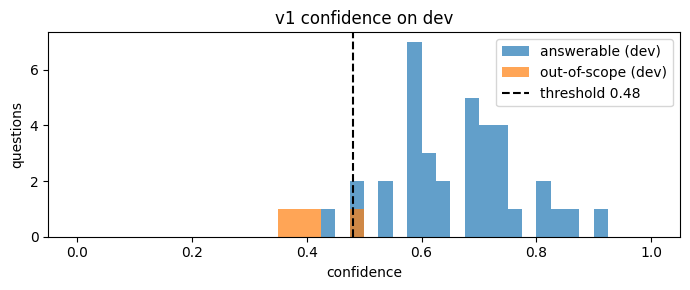

In [23]:
chunks_v1 = make_chunks(segments, BEST_SIZE, overlap=max(20, BEST_SIZE // 4))
v1 = SemanticQA(chunks_v1, beta=BEST_BETA)               # threshold 0 -> confidence does not depend on it
dev_res = run_eval(v1, dev, chunks_v1, "tune")
a, o = dev_res[dev_res.answerable], dev_res[~dev_res.answerable]

# which signal separates "SRB covers this" from "it doesn't"? (AUROC on dev, 36 vs 4 questions)
dev_signals = pd.DataFrame([{**{k: v1.ask(q)[k] for k in ["lexical_coverage", "semantic_similarity", "confidence"]},
                             "answerable": ans} for q, ans in zip(dev.question, dev.answerable)])
print("Dev AUROC (answerable vs out-of-scope):",
      {c: round(roc_auc_score(dev_signals.answerable, dev_signals[c]), 3)
       for c in ["lexical_coverage", "semantic_similarity", "confidence"]})

thresholds = np.round(np.arange(0, 1.0001, 0.01), 2)
curve = pd.DataFrame({
    "threshold": thresholds,
    "answerable_not_refused": [(a.confidence >= t).mean() for t in thresholds],
    "out_of_scope_refused": [(o.confidence < t).mean() for t in thresholds],
})
curve["balanced_acc"] = (curve.answerable_not_refused + curve.out_of_scope_refused) / 2
tied = curve[np.isclose(curve.balanced_acc, curve.balanced_acc.max())].threshold.tolist()
THRESHOLD = float(tied[len(tied) // 2])                  # middle of the best range = largest margin
v1.threshold = THRESHOLD
print(f"Best dev balanced accuracy {curve.balanced_acc.max():.3f} for thresholds {tied[0]}-{tied[-1]} -> chosen {THRESHOLD}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(a.confidence, bins=np.arange(0, 1.01, 0.025), alpha=0.7, label="answerable (dev)")
ax.hist(o.confidence, bins=np.arange(0, 1.01, 0.025), alpha=0.7, label="out-of-scope (dev)")
ax.axvline(THRESHOLD, color="k", ls="--", label=f"threshold {THRESHOLD}")
ax.set_xlabel("confidence"); ax.set_ylabel("questions"); ax.legend(); ax.set_title("v1 confidence on dev")
plt.tight_layout(); plt.show()

## 5. Final evaluation on the held-out test set

All settings are now frozen: chunk size, beta and threshold come from dev only. The test set is used here for the first time for v1.

In [24]:
res_dev_v1 = run_eval(v1, dev, chunks_v1, "final-dev")
res_test_v1 = run_eval(v1, test, chunks_v1, "final-test")

answered = res_test_v1[~res_test_v1.abstained]
grounded = [p in s for p, s in zip(answered.pred_answer, answered.supporting_text)]
assert all(grounded)
print(f"Groundedness: {np.mean(grounded):.0%} of v1 answers are copied verbatim from the cited chunk")

t0 = time.time()
for q in test.question:
    v1.ask(q)
print(f"Latency: {1000 * (time.time() - t0) / len(test):.0f} ms per question on CPU\n")

comparison = pd.DataFrame({"Baseline (Week 2)": summarize(res_test_base), "v1 (Week 3)": summarize(res_test_v1)})
comparison["change"] = comparison["v1 (Week 3)"] - comparison["Baseline (Week 2)"]
comparison.round(3)

Groundedness: 100% of v1 answers are copied verbatim from the cited chunk
Latency: 48 ms per question on CPU



,Baseline (Week 2),v1 (Week 3),change
Hit@1,0.667,0.741,0.074
Hit@3,0.889,0.926,0.037
Hit@5,0.926,0.981,0.056
MRR@5,0.772,0.831,0.059
Citation accuracy (page),0.815,0.907,0.093
Answer accuracy (key fact),0.370,0.593,0.222
Answer accuracy if never refusing,0.500,0.593,0.093
Key fact in supporting text,0.796,0.815,0.019
False abstention (answerable),0.222,0.019,-0.204
Hallucination rate (out-of-scope),0.167,0.333,0.167


,fixed by v1,broken by v1,p-value
Hit@1,7.0,3.0,0.3438
Citation accuracy,6.0,1.0,0.1250
Answer accuracy (key fact),14.0,2.0,0.0042


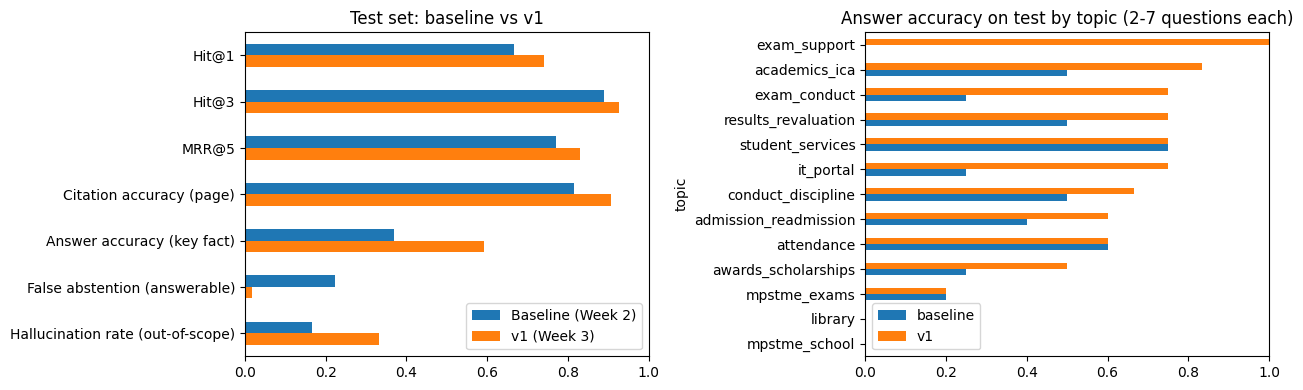

In [25]:
# Paired test (exact McNemar): same 54 answerable test questions, baseline vs v1
def mcnemar(base_ok, new_ok):
    base_ok, new_ok = np.asarray(base_ok, bool), np.asarray(new_ok, bool)
    fixed, broken = int((new_ok & ~base_ok).sum()), int((base_ok & ~new_ok).sum())
    p = binomtest(min(fixed, broken), fixed + broken, 0.5).pvalue if fixed + broken else 1.0
    return {"fixed by v1": fixed, "broken by v1": broken, "p-value": round(p, 4)}

b = res_test_base[res_test_base.answerable].set_index("qid")
n = res_test_v1[res_test_v1.answerable].set_index("qid").loc[b.index]
display(pd.DataFrame({
    "Hit@1": mcnemar(b["rank"] == 1, n["rank"] == 1),
    "Citation accuracy": mcnemar(b.citation_ok, n.citation_ok),
    "Answer accuracy (key fact)": mcnemar(b.answer_ok, n.answer_ok),
}).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
show_rows = ["Hit@1", "Hit@3", "MRR@5", "Citation accuracy (page)", "Answer accuracy (key fact)",
             "False abstention (answerable)", "Hallucination rate (out-of-scope)"]
comparison.loc[show_rows, ["Baseline (Week 2)", "v1 (Week 3)"]].plot.barh(ax=axes[0], xlim=(0, 1),
                                                                           title="Test set: baseline vs v1")
axes[0].invert_yaxis()
by_topic = pd.DataFrame({
    "baseline": res_test_base[res_test_base.answerable].groupby("topic").answer_ok.mean(),
    "v1": res_test_v1[res_test_v1.answerable].groupby("topic").answer_ok.mean()}).sort_values("v1")
by_topic.plot.barh(ax=axes[1], xlim=(0, 1), title="Answer accuracy on test by topic (2-7 questions each)")
plt.tight_layout(); plt.show()

## 6. Ablation and error analysis

### 6.1 Which part of v1 helps? (test set, settings frozen)

Each row adds one piece on top of the previous one. The chunks and threshold are the frozen v1 ones. We report metrics with **no refusals**, so the rows compare retrieval and answer selection only; the refusal part is compared separately with AUROC (answerable vs out-of-scope). This is a post-hoc analysis: nothing here was used to choose settings.

In [26]:
class KeywordSentenceOnV1(SemanticQA):
    """ablation helper: v1 retrieval but the Week-2 keyword rule for picking the answer sentence"""
    def select_answer(self, ci, sent_sim):
        answer = extract_answer(self._q, self.chunks.text[ci])
        idx = np.flatnonzero(self.sent_chunk == ci)
        return answer, float(sent_sim[idx].max())
    def ask(self, question):
        self._q = question
        return super().ask(question)

variants = {
    "A. Week-2 method: BM25 + keyword sentence": KeywordQA(chunks_v1, BM25Retriever),
    "B. BM25 + semantic sentence (beta = 0)": SemanticQA(chunks_v1, beta=0.0),
    "C. Embeddings only + semantic sentence (beta = 1)": SemanticQA(chunks_v1, beta=1.0),
    "D. Hybrid + keyword sentence": KeywordSentenceOnV1(chunks_v1, beta=BEST_BETA),
    f"E. v1: hybrid (beta = {BEST_BETA}) + semantic sentence": SemanticQA(chunks_v1, beta=BEST_BETA),
}
abl = {}
for name, system in variants.items():
    s = summarize(run_eval(system, test, chunks_v1, "final-test"))
    abl[name] = s[["Hit@1", "MRR@5", "Citation accuracy (page)", "Answer accuracy if never refusing"]]
display(pd.DataFrame(abl).T.round(3))

# refusal signal: AUROC answerable vs out-of-scope on test (v1 retrieval, all three confidence signals)
test_signals = pd.DataFrame([{**{k: v1.ask(q)[k] for k in ["lexical_coverage", "semantic_similarity", "confidence"]},
                              "answerable": ans} for q, ans in zip(test.question, test.answerable)])
base_auc = roc_auc_score(res_test_base.answerable, res_test_base.confidence)
print("Test AUROC answerable vs out-of-scope:",
      {"baseline keyword confidence": round(base_auc, 3),
       **{f"v1 {c}": round(roc_auc_score(test_signals.answerable, test_signals[c]), 3)
          for c in ["lexical_coverage", "semantic_similarity", "confidence"]}})

,Hit@1,MRR@5,Citation accuracy (page),Answer accuracy if never refusing
A. Week-2 method: BM25 + keyword sentence,0.667,0.761,0.852,0.500
B. BM25 + semantic sentence (beta = 0),0.667,0.761,0.852,0.537
C. Embeddings only + semantic sentence (beta = 1),0.593,0.710,0.796,0.481
D. Hybrid + keyword sentence,0.741,0.831,0.907,0.556
E. v1: hybrid (beta = 0.6) + semantic sentence,0.741,0.831,0.907,0.593


Test AUROC answerable vs out-of-scope: {'baseline keyword confidence': np.float64(0.863), 'v1 lexical_coverage': np.float64(0.881), 'v1 semantic_similarity': np.float64(0.975), 'v1 confidence': np.float64(0.985)}


### 6.2 Error analysis (test set)

Same buckets as Week 2, so the two notebooks can be compared bucket by bucket.

In [27]:
def buckets(res):
    e = res[res.answerable].copy()
    e["outcome"] = np.select(
        [e.answer_ok, e.abstained, e["rank"] != 1],
        ["correct", "refused (low confidence)", "retrieval miss (wrong passage ranked first)"],
        default="right passage, wrong sentence picked")
    return e

errs_base, errs_v1 = buckets(res_test_base), buckets(res_test_v1)
display(pd.DataFrame({"baseline": errs_base.outcome.value_counts(), "v1": errs_v1.outcome.value_counts()})
        .fillna(0).astype(int).loc[["correct", "retrieval miss (wrong passage ranked first)",
                                    "right passage, wrong sentence picked", "refused (low confidence)"]])

for outcome in ["retrieval miss (wrong passage ranked first)", "right passage, wrong sentence picked",
                "refused (low confidence)"]:
    print(f"--- v1: {outcome} ---")
    for r in errs_v1[errs_v1.outcome == outcome].head(3).itertuples():
        print(f"Q: {r.question}  (confidence {r.confidence})\n   gold : {r.gold_answer}\n   v1   : {r.pred_answer[:170]}\n")

oos = res_test_v1[~res_test_v1.answerable][["question", "confidence", "abstained", "pred_answer"]]
print("--- v1 on the out-of-scope test questions ---")
display(oos)

,baseline,v1
outcome,,
correct,20,32
retrieval miss (wrong passage ranked first),12,12
"right passage, wrong sentence picked",10,9
refused (low confidence),12,1


--- v1: retrieval miss (wrong passage ranked first) ---
Q: Is there a re-exam if I fail an only-ICA course?  (confidence 0.715)
   gold : No. There is no re-exam for only-ICA courses; you must take re-admission.
   v1   : If a student does not pass only ICA course, he/she must take re-admission in the same trimester/semester/annual term of the subsequent academic year of the program, or ma

Q: What is the punishment for trying to bribe an examiner?  (confidence 0.6)
   gold : Exclusion from four additional examinations; the money goes to the Students Welfare Fund.
   v1   : 9.1.14 Any method to bribe the examiner/s by

Q: What percentage of students make it to the Dean's list?  (confidence 0.595)
   gold : The top 10% of the batch by CGPA.
   v1   : given to the next ranking students. 10.5 Rankings would always be decided at University level.

--- v1: right passage, wrong sentence picked ---
Q: When will my parents be informed about my attendance?  (confidence 0.816)
   gold : If your 

,question,confidence,abstained,pred_answer
54,What is the annual tuition fee for B Tech Data Science?,0.507,False,"However, candidates opting for B Tech Computer Science and Engineering will be enrolled in B Tech Data Sci..."
55,What time does the college canteen close?,0.302,True,I could not find this in the Student Resource Book.
56,Is there a gym on campus and what are its timings?,0.396,True,I could not find this in the Student Resource Book.
57,What is the average placement package for B Tech students?,0.503,False,"MBA Tech Program has 2 internships, Technical Internship post 6 Semester -8 weeks and Management Internshi..."
58,Is there a college shuttle bus from the railway station?,0.231,True,I could not find this in the Student Resource Book.
59,How much is the parking fee for two-wheelers on campus?,0.459,True,I could not find this in the Student Resource Book.


## 7. Pipeline in action

In [28]:
for q in ["What is the minimum attendance required to appear for the end-semester exam?",   # proposal example
          "How much is the late fine for a library book?",                                   # baseline picked the wrong sentence
          "Is a smart watch allowed in the exam hall?",
          "What is the hostel curfew time for students?"]:                                   # not in the SRB
    show(v1.ask(q), q)

Q: What is the minimum attendance required to appear for the end-semester exam?
  answer         : Attendance requirements are summarised hereunder: Attendance% (In Individual Courses) Remarks 80% and above In individual courses Eligible to appear for Trimester/Semester/Annual term End Examinations.
  source         : SRB 2026 | Part I (University) | 3. Attendance Rules | PDF page 11
  confidence     : 0.626
  supporting_text: Students who have maintained 80% or higher attendance in individual courses during a trimester/semester/annual term are eligible to appear for the respective trimester/semester/annual term-end examinations. Attendance is...

Q: How much is the late fine for a library book?
  answer         : 14.13 A fine of Rs.3.00 per day per book is levied on overdue books.
  source         : SRB 2026 | Part I (University) | 14. Library Rules | PDF page 30
  confidence     : 0.733
  supporting_text: fine or disciplinary action. 14.12 Borrowing entitlement: Two books for ten day

## 8. Tests against the requirements

* **8.1 Unit tests** check each part of the NLP component on its own.
* **8.2 Requirement tests** check the Week-3 deliverable and our proposal's requirements end to end.

Every line prints PASS or FAIL, and the cell stops with an error if anything fails.
After the requirement tests, a **result scorecard** shows metric by metric whether v1 beats the baseline on test. It is reported, not asserted, because a result can honestly go either way.

In [29]:
unit = {}

# embeddings
E = embed(["attendance rules", "library fine", ""])
unit["Embeddings: 384-dim, L2-normalised, finite"] = (E.shape == (3, 384) and np.allclose(np.linalg.norm(E, axis=1), 1, atol=1e-4)
                                                      and np.isfinite(E).all())
unit["Embeddings: deterministic"] = np.allclose(embed(["attendance rules"]), embed(["attendance rules"]), atol=1e-6)
unit["Semantic similarity: paraphrase > unrelated rule"] = sims[0] > max(sims[1:])      # §3 example
lens = np.array([len(encoder.tokenizer(t)["input_ids"]) for t in v1.sent_inputs])
unit["Embeddings: no sentence truncated (<= max_seq_length)"] = bool((lens <= encoder.max_seq_length).all())
print(f"(sentence length: mean {lens.mean():.0f} tokens, max {lens.max()}, limit {encoder.max_seq_length})")

# index
unit["Index: every sentence is a verbatim substring of its chunk"] = all(
    s in v1.chunks.text[ci] for ci, s in zip(v1.sent_chunk, v1.sent_text))
unit["Index: every chunk has >= 1 sentence and one embedding per sentence"] = (
    set(v1.sent_chunk) == set(range(len(v1.chunks))) and len(v1.sent_emb) == len(v1.sent_text))
seg_texts = segments.groupby(["page", "section"]).text.apply(list)
unit["Chunks: never cross a page or section"] = all(
    any(t in s for s in seg_texts[(p, sec)]) for p, sec, t in zip(chunks_v1.page, chunks_v1.section, chunks_v1.text))

# retrieval
hits = v1.search("How many library books can I borrow?", k=5)
unit["Search: k distinct chunks, scores sorted, in [0, 1]"] = (
    len({c for c, _ in hits}) == 5 and all(hits[i][1] >= hits[i + 1][1] for i in range(4))
    and all(0 <= s <= 1 for _, s in hits))
unit["minmax: constant input -> zeros (no division by zero)"] = np.array_equal(minmax([2.0, 2.0]), np.zeros(2))

# answer / confidence / abstention
out = v1.ask("How many library books can I borrow?")
unit["Answer: copied verbatim from the cited chunk"] = out["extracted"] in out["supporting_text"]
unit["Confidence: in [0, 1] and = mean(lexical, semantic)"] = (
    0 <= out["confidence"] <= 1 and abs(out["confidence"] - (out["lexical_coverage"] + out["semantic_similarity"]) / 2) < 2e-3)
unit["Same question -> same output"] = v1.ask("Can I eat in the classroom?") == v1.ask("Can I eat in the classroom?")
unit["Empty / stop-word-only question -> refuses"] = v1.ask("")["abstained"] and v1.ask("what is the")["abstained"]
unit["Gibberish question -> refuses"] = v1.ask("zxqv blorf wibble")["abstained"]

for name, ok in unit.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(unit.values())

(sentence length: mean 34 tokens, max 203, limit 256)
PASS - Embeddings: 384-dim, L2-normalised, finite
PASS - Embeddings: deterministic
PASS - Semantic similarity: paraphrase > unrelated rule
PASS - Embeddings: no sentence truncated (<= max_seq_length)
PASS - Index: every sentence is a verbatim substring of its chunk
PASS - Index: every chunk has >= 1 sentence and one embedding per sentence
PASS - Chunks: never cross a page or section
PASS - Search: k distinct chunks, scores sorted, in [0, 1]
PASS - minmax: constant input -> zeros (no division by zero)
PASS - Answer: copied verbatim from the cited chunk
PASS - Confidence: in [0, 1] and = mean(lexical, semantic)
PASS - Same question -> same output
PASS - Empty / stop-word-only question -> refuses
PASS - Gibberish question -> refuses


In [30]:
test_metrics = summarize(res_test_v1)
tuning_qids = set().union(*[q for stage, q in EVAL_LOG if stage == "tune"])
all_out = [v1.ask(q) for q in test.question]
kb_pages = set(pages.page)

req = {
    # Week-3 deliverable
    "Primary NLP component implemented: sentence embeddings used for retrieval, answer selection and confidence":
        isinstance(v1, SemanticQA) and v1.sent_emb.shape[1] == EMB_DIM and 0 < v1.beta <= 1,
    "Pipeline v1 runs end to end on every test question":
        len(all_out) == len(test),
    # proposal: output format
    "Every output has answer, source, confidence, supporting_text":
        all({"answer", "source", "confidence", "supporting_text"} <= o.keys() for o in all_out),
    "Every source names part, section and a PDF page that is in the knowledge base":
        all(o["abstained"] or (o["cited_page"] in kb_pages and f"PDF page {o['cited_page']}" in o["source"]) for o in all_out),
    "Grounded: every answer is copied verbatim from its cited chunk (no invented text)":
        all(o["abstained"] or o["answer"] in o["supporting_text"] for o in all_out),
    "Refusals use the fixed 'not found' message":
        all(o["answer"] == SemanticQA.NOT_FOUND for o in all_out if o["abstained"]),
    # proposal: evaluation
    "All four proposal metrics computed on test (retrieval, citation, answer, hallucination)":
        test_metrics[["Hit@1", "MRR@5", "Citation accuracy (page)", "Answer accuracy (key fact)",
                      "Hallucination rate (out-of-scope)"]].notna().all(),
    "Same test set and same metric code as the Week-2 baseline (baseline reproduced exactly)":
        not mismatch,
    "No test question used for tuning (all tuning runs used dev only)":
        tuning_qids == set(dev.qid) and tuning_qids.isdisjoint(test.qid),
}
for name, ok in req.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(req.values())

# Result scorecard (not a pass/fail requirement): is v1 better than the baseline on each proposal metric?
higher_is_better = {"Hit@1": True, "MRR@5": True, "Citation accuracy (page)": True,
                    "Answer accuracy (key fact)": True, "False abstention (answerable)": False,
                    "Hallucination rate (out-of-scope)": False}
scorecard = pd.DataFrame({
    "baseline": [base_summary[m] for m in higher_is_better], "v1": [test_metrics[m] for m in higher_is_better],
    "v1 better?": ["yes" if (test_metrics[m] > base_summary[m]) == hib and test_metrics[m] != base_summary[m]
                   else "no" for m, hib in higher_is_better.items()]}, index=list(higher_is_better)).round(3)
print("\nResult scorecard on test:")
scorecard

PASS - Primary NLP component implemented: sentence embeddings used for retrieval, answer selection and confidence
PASS - Pipeline v1 runs end to end on every test question
PASS - Every output has answer, source, confidence, supporting_text
PASS - Every source names part, section and a PDF page that is in the knowledge base
PASS - Grounded: every answer is copied verbatim from its cited chunk (no invented text)
PASS - Refusals use the fixed 'not found' message
PASS - All four proposal metrics computed on test (retrieval, citation, answer, hallucination)
PASS - Same test set and same metric code as the Week-2 baseline (baseline reproduced exactly)
PASS - No test question used for tuning (all tuning runs used dev only)

Result scorecard on test:


,baseline,v1,v1 better?
Hit@1,0.667,0.741,yes
MRR@5,0.772,0.831,yes
Citation accuracy (page),0.815,0.907,yes
Answer accuracy (key fact),0.370,0.593,yes
False abstention (answerable),0.222,0.019,yes
Hallucination rate (out-of-scope),0.167,0.333,no


## 9. Saved outputs and summary

In [31]:
config = {"embedding_model": EMB_MODEL, "embedding_dim": int(EMB_DIM), "chunk_size": BEST_SIZE,
          "chunk_overlap": max(20, BEST_SIZE // 4), "beta": BEST_BETA, "threshold": THRESHOLD, "top_k": v1.k,
          "sentence_prefix": "section title", "confidence": "mean(keyword coverage, answer-sentence cosine)"}
json.dump(config, open(f"{OUT_DIR}/v1_config.json", "w"), indent=2)
grid.to_csv(f"{OUT_DIR}/v1_dev_tuning_grid.csv", index=False)
comparison.to_csv(f"{OUT_DIR}/v1_vs_baseline_metrics.csv")
res_test_v1.drop(columns="supporting_text").to_csv(f"{OUT_DIR}/v1_test_predictions.csv", index=False)
chunks_v1.to_csv(f"{OUT_DIR}/v1_chunks.csv", index=False)
np.save(f"{OUT_DIR}/v1_sentence_embeddings.npy", v1.sent_emb)
pd.DataFrame({"chunk_id": [v1.ids[c] for c in v1.sent_chunk], "sentence": v1.sent_text}).to_csv(
    f"{OUT_DIR}/v1_sentences.csv", index=False)
print(json.dumps(config, indent=2))
print("Saved:", sorted(os.listdir(OUT_DIR)))

{
  "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
  "embedding_dim": 384,
  "chunk_size": 100,
  "chunk_overlap": 25,
  "beta": 0.6,
  "threshold": 0.48,
  "top_k": 5,
  "sentence_prefix": "section title",
  "confidence": "mean(keyword coverage, answer-sentence cosine)"
}
Saved: ['v1_chunks.csv', 'v1_config.json', 'v1_dev_tuning_grid.csv', 'v1_sentence_embeddings.npy', 'v1_sentences.csv', 'v1_test_predictions.csv', 'v1_vs_baseline_metrics.csv']


### Summary

**What v1 adds.** One NLP component: `all-MiniLM-L6-v2` sentence embeddings. They are used in three places: hybrid retrieval (BM25 + best-sentence cosine), picking the answer sentence, and the confidence score used to refuse. Answers are still copied word for word from the cited chunk, so v1 never invents text.

**Settings (chosen on dev only).** Chunk size 100 words, beta = 0.6 (60% semantic, 40% BM25), refusal threshold 0.48.

**Results on the held-out test set** (same 54 answerable + 6 out-of-scope questions and same metric code as Week 2):

| Metric | Baseline (Week 2) | v1 (Week 3) |
|---|---|---|
| Hit@1 / MRR@5 | 0.667 / 0.772 | **0.741 / 0.831** |
| Citation accuracy (page) | 0.815 | **0.907** |
| Answer accuracy (key fact) | 0.370 | **0.593** |
| False abstention (answerable) | 0.222 | **0.019** |
| Hallucination rate (out-of-scope) | **0.167** (1 of 6) | 0.333 (2 of 6) |

**What we learned.**
1. **Answer accuracy is the big gain: +22 points.** v1 fixes 14 test questions and breaks 2 (exact McNemar test, p = 0.004). The gain comes from far fewer wrong refusals and from better sentence choice. On the same retrieval, the semantic sentence beats the keyword sentence by 3.7 points (ablation D vs E).
2. **Hybrid retrieval beats both of its parts.** Embeddings alone are worse than BM25 (Hit@1 0.593 vs 0.667), because the SRB is full of exact terms (ATKT, ICA, NSP) and MiniLM is a small model. Mixing the two gives the best ranking (Hit@1 0.741). The Hit@1 gain is not yet statistically significant (7 fixed, 3 broken, p = 0.34).
3. **Refusal: better signal, but the threshold leaks one more question.** v1 answered 2 of 6 out-of-scope test questions (tuition fee, placement package) against 1 of 6 for the baseline. Both are just above the threshold (0.507 and 0.503 vs 0.48). The confidence itself separates answerable from out-of-scope much better than in Week 2 (test AUROC 0.985 vs 0.863), so the weak point is the threshold, which was tuned on only 4 out-of-scope dev questions. We report this as is and do not re-tune on test.
4. **Remaining errors (54 answerable test questions):** 12 retrieval misses, 9 right passage but wrong sentence, 1 wrong refusal.

**Next (v2).**
* Write more out-of-scope dev questions so the threshold is calibrated on more than 4 examples.
* Re-rank the top 5 with a cross-encoder: the right chunk is already in the top 5 for 98% of test questions, but first for only 74%.
* Let an LLM write the final answer only from the retrieved chunks, and keep the grounding check.
* Compare a larger embedding model (e.g. `bge-base-en-v1.5`) on dev.

*These numbers come from a CPU run of this notebook. The model runs on CPU and nothing is random, so a re-run should give the same numbers (tiny differences are possible with other library versions).*